1) Инициализация

In [76]:
from common import load_data, split, prepare, outliers
X, y = load_data()
print(X.head()) # Проверка подгрузки данных

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


corr_threshold = 0.99 # correlation_threshold

         mean_1        mean_2    mean_3    mean_4        mean_5    mean_6  \
0 -3.014600e-07  8.260300e-06 -0.000012 -0.000002 -1.438600e-06 -0.000021   
1  2.913200e-06 -5.247700e-06  0.000003 -0.000006  2.778900e-06 -0.000004   
2 -2.951700e-06 -3.184000e-06 -0.000016 -0.000001 -1.575300e-06  0.000017   
3 -1.322600e-06  8.820100e-06 -0.000016 -0.000005 -7.282900e-07  0.000004   
4 -6.836600e-08  5.666300e-07 -0.000026 -0.000006 -7.940600e-07  0.000013   

     mean_7    mean_8    mean_9   mean_10  ...   kurt_3   kurt_4  kurt_5  \
0  0.031718  0.031710  0.031721 -0.032963  ...   6.0168 -0.63308  2.9646   
1  0.030804  0.030810  0.030806 -0.033520  ...   3.6048 -0.59314  7.6252   
2  0.032877  0.032880  0.032896 -0.029834  ...   5.8007 -0.63252  2.7784   
3  0.029410  0.029401  0.029417 -0.030156  ...  23.3960 -0.62289  6.5534   
4  0.030119  0.030119  0.030145 -0.031393  ...   5.0582 -0.63010  4.5155   

   kurt_6  kurt_7  kurt_8  kurt_9  kurt_10  kurt_11  kurt_12  
0  8.1198 -1.4961

2) 

Столбцы, которые можно удалить: ['mean_8', 'mean_9', 'mean_11', 'mean_12', 'std_8', 'std_9', 'std_10', 'std_11', 'std_12', 'skew_8', 'skew_9', 'skew_11', 'skew_12', 'kurt_8', 'kurt_9', 'kurt_11', 'kurt_12']


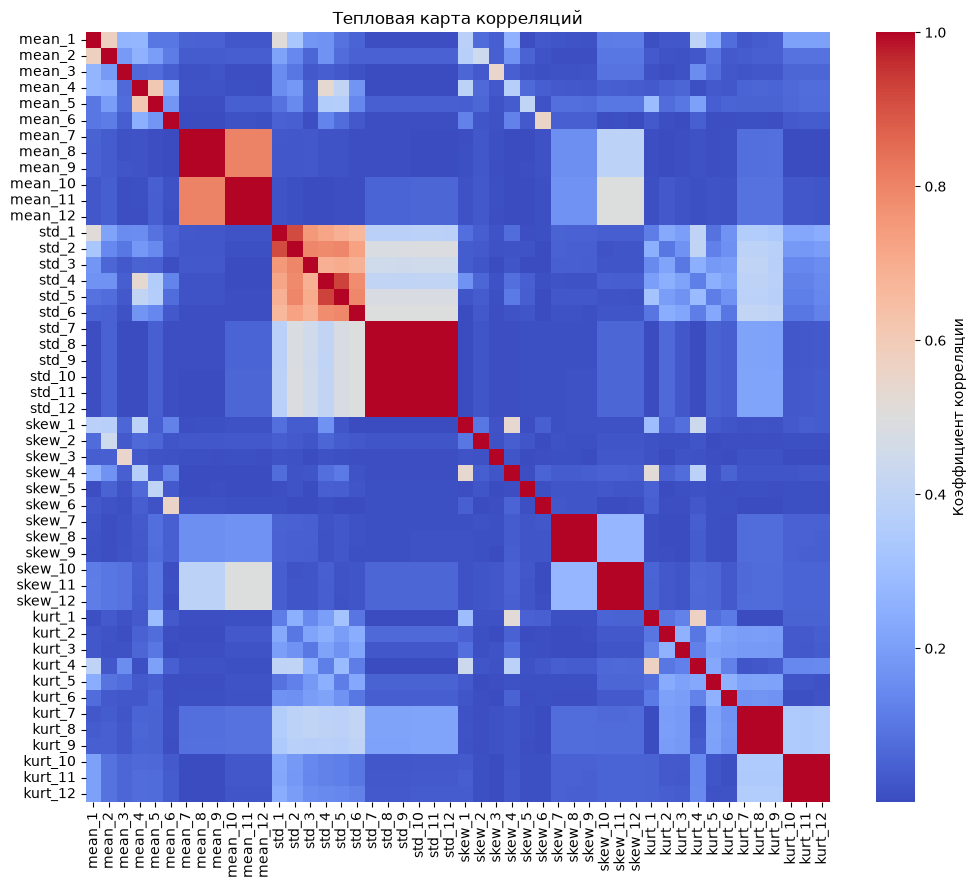

In [77]:
corr_matrix = X.corr().abs() # Матрица корреляций

# Только верхний треугольник без главной диагонали
upper = corr_matrix.where(pd.DataFrame(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool), 
                                       index=corr_matrix.index, columns=corr_matrix.columns))

# Столбцы с корреляцией > corr_threshold
to_drop = [column for column in upper.columns if any(upper[column] > corr_threshold)]
print(f"Столбцы, которые можно удалить: {to_drop}")

# Тепловая карта
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap='coolwarm', cbar_kws={'label': 'Коэффициент корреляции'})
plt.title("Тепловая карта корреляций")
plt.savefig('correlation_heatmap.png') # Сохраняем в папку figures
plt.show()

3) Визуализация

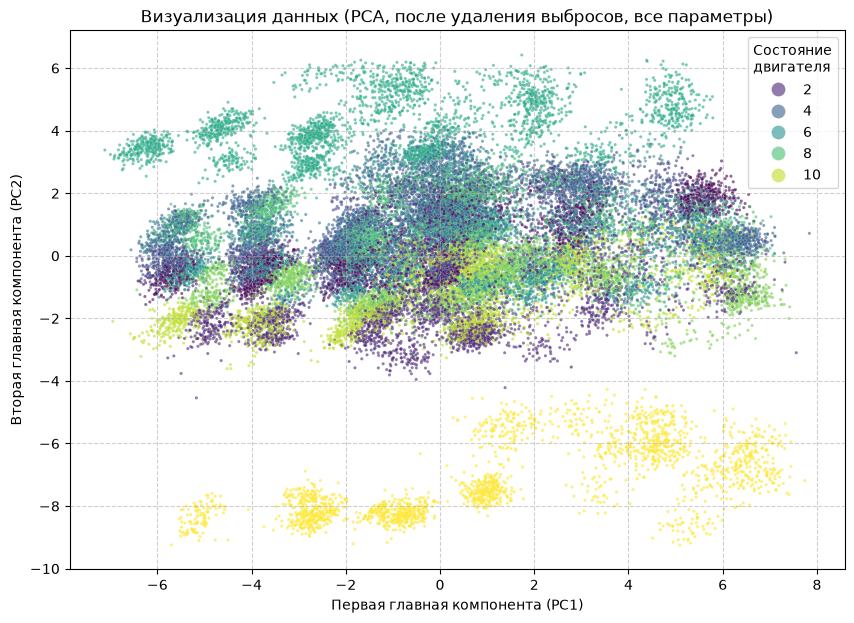

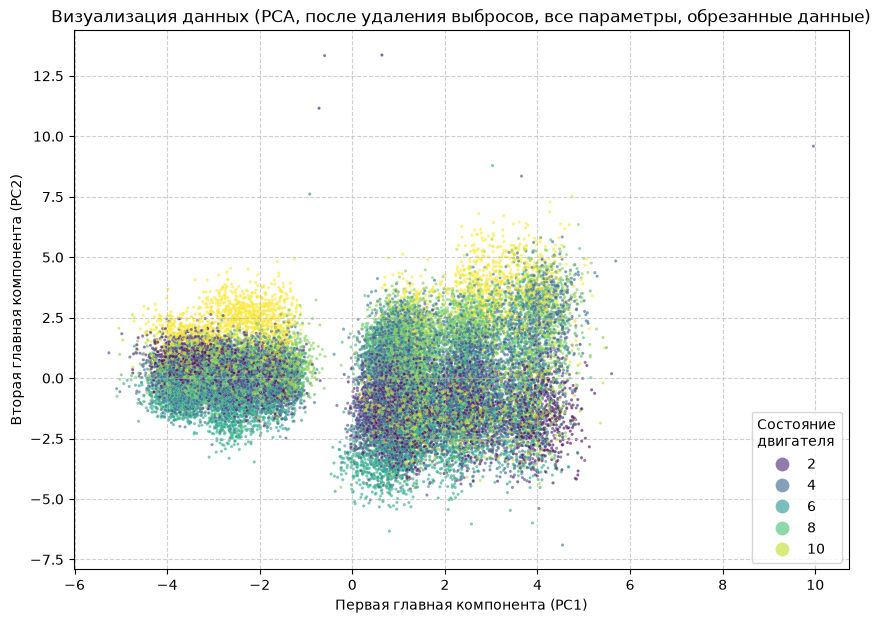

Объясненная дисперсия: [0.21567379 0.095375  ]
Общая объясненная дисперсия (в процентах): 31.10%


In [ ]:
# Готовый сплит
X_train, X_test, y_train, y_test = split(X, y)

# Готовая нормализация
X_train_scaled, X_test_scaled = prepare(X_train, X_test)


# БЕЗ УДАЛЕНИЯ ПАРАМЕТРОВ
'''# PCA визуализация с выбросами
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train_scaled)

plt.figure(figsize=(10, 7))
scatter = sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_train, palette='viridis', alpha=0.6, s=5, linewidth=0.1)
handles, labels = scatter.get_legend_handles_labels()
for handle in handles:
    handle.set_markersize(10)
plt.title("Визуализация данных (PCA, без удаления выбросов, все параметры)")
plt.xlabel("Первая главная компонента (PC1)")
plt.ylabel("Вторая главная компонента (PC2)")
legend = plt.legend(title="Состояние\nдвигателя", loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)

plt.savefig('pca_plot.png')
plt.show()'''

# PCA визуализация без выбросов
# Маска выбросов
mask = outliers(X_train, X_train)
rows_with_outliers = mask.any(axis=1)

# Оставляем только те строки, где выбросов нет
X_train_clean = X_train[~rows_with_outliers]
y_train_clean = y_train[~rows_with_outliers]

# Нормализация эти «чистых» данных
scaler = StandardScaler() 
X_train_scaled = scaler.fit_transform(X_train_clean)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train_scaled)

plt.figure(figsize=(10, 7))
scatter = sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_train_clean, palette='viridis', alpha=0.6, s=5, linewidth=0.1)
handles, labels = scatter.get_legend_handles_labels()
for handle in handles:
    handle.set_markersize(10)
plt.title("Визуализация данных (PCA, после удаления выбросов, все параметры)")
plt.xlabel("Первая главная компонента (PC1)")
plt.ylabel("Вторая главная компонента (PC2)")
legend = plt.legend(title="Состояние\nдвигателя", loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig('pca_clean_plot.png')
plt.show()


# С УДАЛЕНИЕМ ПАРАМЕТРОВ
# PCA визуализация без выбросов
# Удаляем лишние столбцы
X_train_reduced = X_train.drop(columns=to_drop)
# Маска выбросов
mask = outliers(X_train_reduced, X_train_reduced)
rows_with_outliers = mask.any(axis=1)

# Оставляем только те строки, где выбросов нет
X_train_clean = X_train_reduced[~rows_with_outliers]
y_train_clean = y_train[~rows_with_outliers]

# Нормализация эти «чистых» данных
scaler = StandardScaler() 
X_train_scaled = scaler.fit_transform(X_train_clean)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train_scaled)

plt.figure(figsize=(10, 7))
scatter = sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_train_clean, palette='viridis', alpha=0.6, s=5, linewidth=0.1)
handles, labels = scatter.get_legend_handles_labels()
for handle in handles:
    handle.set_markersize(10)
plt.title("Визуализация данных (PCA, после удаления выбросов, все параметры, обрезанные данные)")
plt.xlabel("Первая главная компонента (PC1)")
plt.ylabel("Вторая главная компонента (PC2)")

legend = plt.legend(title="Состояние\nдвигателя", loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig('pca_clean_plot_DropOutlets.png')
plt.show()


# Гипотеза Г4: проверка объясненной дисперсии
print(f"Объясненная дисперсия: {pca.explained_variance_ratio_}")
# Общую информация о "качестве" сжатия
total_variance = sum(pca.explained_variance_ratio_)
print(f"Общая объясненная дисперсия (в процентах): {total_variance * 100:.2f}%")

Г4 ОПРОВЕРГНУТА: 31.10% < 50%

4. Перепроверка TSNE

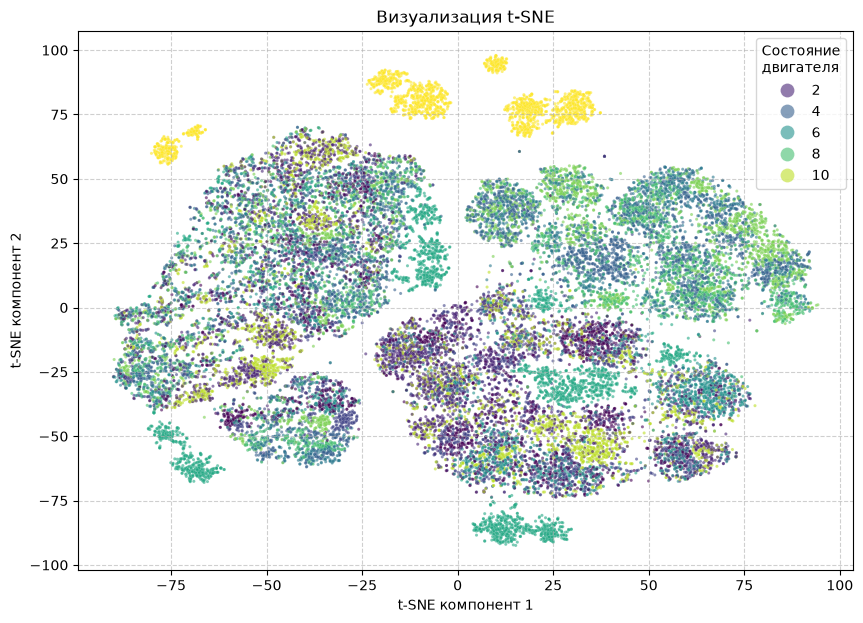

In [79]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X_train_scaled)

plt.figure(figsize=(10, 7))
scatter = sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=y_train_clean, palette='viridis', alpha=0.6, s=5, linewidth=0.1)
handles, labels = scatter.get_legend_handles_labels()
for handle in handles:
    handle.set_markersize(10)

plt.title("Визуализация t-SNE")
plt.legend(title="Состояние\nдвигателя", loc='upper right')
plt.xlabel("t-SNE компонент 1")
plt.ylabel("t-SNE компонент 2")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


Четкие кластеры: жёлтые (класс 10) сверху и бирюзовые (класс 6) снизу сформировали компактные группы. Это значит, что для этих состояний двигателя существуют уникальные комбинации признаков, которые алгоритмы машинного обучения смогут легко найти.

Основная масса данных - все цвета перемешаны в центре. Это говорит о том, что для большинства классов различия не столь очевидны, и они имеют схожие характеристики. Модели может потребоваться более сложная настройка.

Скрытая структура: t-SNE показал, что данные не являются «хаотичной кучей», а имеют сложную, нелинейную структуру (островки и переходы).